In [34]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('/home/user/c23052501/PhD_Analysis_Work/cairn.mplstyle')

In [62]:
input_T = np.fromfile('../test_input/sf_input_sur1_tng_T.bin', dtype=np.float64)
input_vel = np.fromfile('../test_input/sf_input_sur1_tng_vel.bin', dtype=np.float64)
input_pos = np.fromfile('../test_input/sf_input_sur1_tng_pos.bin', dtype=np.float64)

# reshape the velocity and position arrays to have shape (N, 3)
input_vel = input_vel.reshape(-1, 3)
input_pos = input_pos.reshape(-1, 3)

In [63]:
len(input_T), len(input_vel), len(input_pos)

(515828, 515828, 515828)

In [64]:
random_indices = np.random.choice(len(input_T), size=100000, replace=False)
sampled_input_T = input_T[random_indices]
sampled_input_vel = input_vel[random_indices]
sampled_input_pos = input_pos[random_indices]

In [65]:
# write the sampled data to new binary files
sampled_input_T.tofile('../test_input/sf_sampled_input_T.bin')
sampled_input_vel.tofile('../test_input/sf_sampled_input_vel.bin')
sampled_input_pos.tofile('../test_input/sf_sampled_input_pos.bin')

In [49]:
bins = np.fromfile('sf_test_bin_edges.bin', dtype=np.float64)
counts = np.fromfile('sf_test_counts.bin', dtype=np.float64)
vsf = np.fromfile('sf_test_velocity_VectorDifference_order_2.bin', dtype=np.float64)
tsf = np.fromfile('sf_test_T_ScalarDifference_order_2.bin', dtype=np.float64)

/tmp/ipykernel_651249/2513464977.py:1: RuntimeWarning: invalid value encountered in divide
  plt.plot(bins, tsf / counts, label='Velocity SF')


Text(0, 0.5, 'SF')

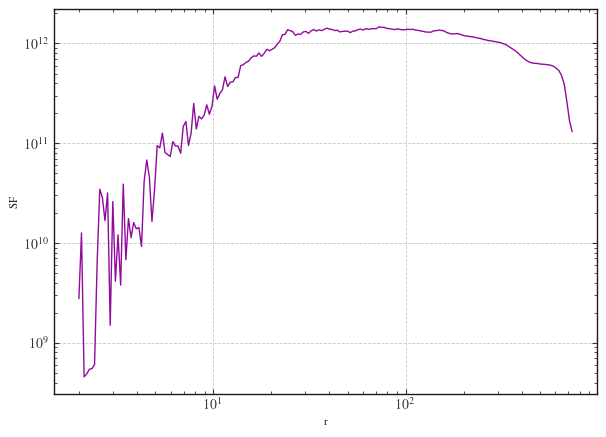

In [50]:
plt.plot(bins, tsf / counts, label='TSF')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('r')
plt.ylabel('SF')

/tmp/ipykernel_651249/4073452622.py:1: RuntimeWarning: invalid value encountered in divide
  plt.plot(bins, vsf / counts, label='TSF')


Text(0, 0.5, 'SF')

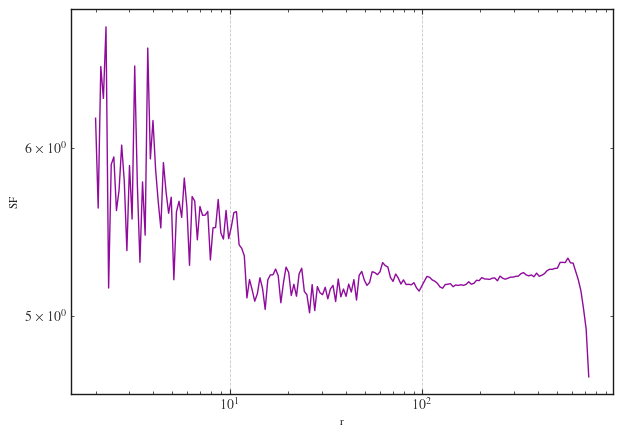

In [51]:
plt.plot(bins, vsf / counts, label='TSF')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('r')
plt.ylabel('SF')

- 16T: 19.658u 0.007s 0:02.55 770.5%   0+0k 0+32io 0pf+0w
- 8T:  20.108u 0.015s 0:02.73 736.6%   0+0k 0+32io 0pf+0w
- 4T:  12.743u 0.019s 0:03.27 389.9%   0+0k 0+32io 0pf+0w
- 2T:  12.292u 0.004s 0:06.33 194.1%   0+0k 0+32io 0pf+0w
- 1T:  11.824u 0.004s 0:11.84 99.8%    0+0k 0+32io 0pf+0w

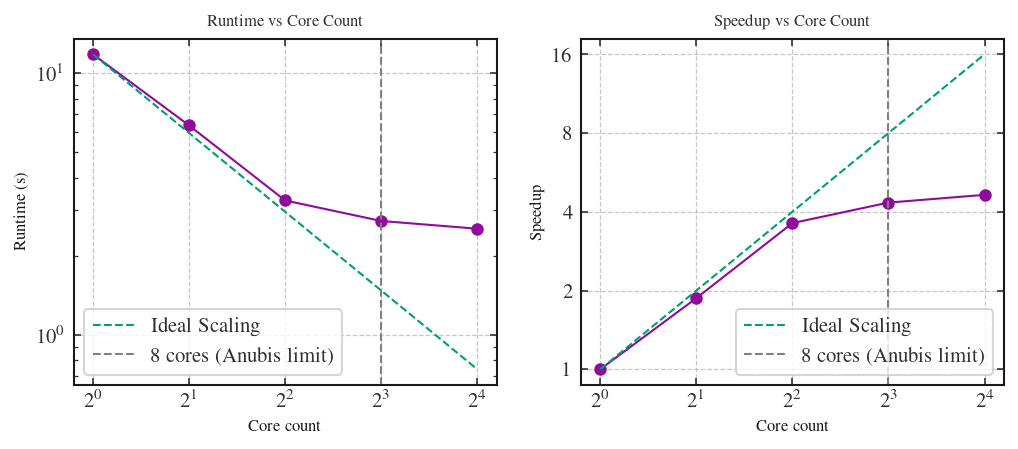

In [83]:
core_counts = np.array([1, 2, 4, 8, 16])
runtimes = np.array([11.84, 6.33, 3.27, 2.73, 2.55])

fig, axes = plt.subplots(1,2,figsize=(8,3), dpi=150)
axes[0].plot(core_counts, runtimes, marker='o')
axes[0].plot(core_counts, 1 / core_counts * runtimes[0], linestyle='--', label='Ideal Scaling')
axes[0].axvline(x=8, color='grey', linestyle='--', label='8 cores (Anubis limit)')
axes[0].set_xscale('log', base=2)
axes[0].set_yscale('log', base=10)
axes[0].set_xlabel('Core count')
axes[0].set_ylabel('Runtime (s)')
axes[0].set_title('Runtime vs Core Count')
axes[0].legend(loc='lower left')
axes[0].grid(True)

axes[1].plot(core_counts, runtimes[0] / runtimes, marker='o')
axes[1].plot(core_counts, core_counts, linestyle='--', label='Ideal Scaling')
axes[1].axvline(x=8, color='grey', linestyle='--', label='8 cores (Anubis limit)')
axes[1].set_xscale('log', base=2)
axes[1].set_yscale('log', base=2)
axes[1].set_yticks([1, 2, 4, 8, 16])
axes[1].set_yticklabels(['1', '2', '4', '8', '16'])
axes[1].set_xlabel('Core count')
axes[1].set_ylabel('Speedup')
axes[1].set_title('Speedup vs Core Count')
axes[1].legend(loc='lower right')

plt.show()

- 1T: 47.349u 0.019s 0:47.39 99.9%    0+0k 0+32io 0pf+0w
- 2T: 49.737u 0.019s 0:25.68 193.6%   0+0k 0+32io 0pf+0w
- 4T: 50.401u 0.031s 0:13.29 379.4%   0+0k 0+32io 0pf+0w
- 6T: 62.502u 0.028s 0:11.51 543.1%   0+0k 0+32io 0pf+0w
- 8T: 78.752u 0.015s 0:10.69 736.7%   0+0k 0+32io 0pf+0w

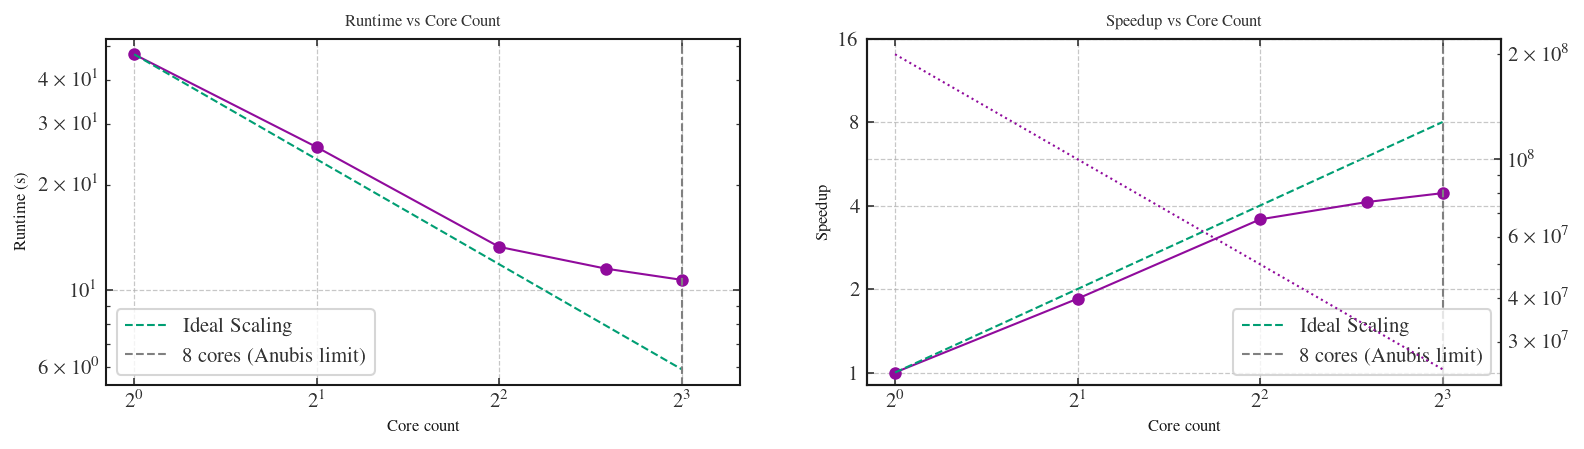

In [93]:
core_counts = np.array([1, 2, 4, 6, 8])
runtimes = np.array([47.39, 25.68, 13.29, 11.51, 10.69])

fig, axes = plt.subplots(1,2,figsize=(12,3), dpi=150)
axes[0].plot(core_counts, runtimes, marker='o')
axes[0].plot(core_counts, 1 / core_counts * runtimes[0], linestyle='--', label='Ideal Scaling')
axes[0].axvline(x=8, color='grey', linestyle='--', label='8 cores (Anubis limit)')
axes[0].set_xscale('log', base=2)
axes[0].set_yscale('log', base=10)
axes[0].set_xlabel('Core count')
axes[0].set_ylabel('Runtime (s)')
axes[0].set_title('Runtime vs Core Count')
axes[0].legend(loc='lower left')
axes[0].set_xlim(0.9,10)
axes[0].grid(True)

N_pairs = 20000*(20000-1)/2
axes[1].plot(core_counts, runtimes[0] / runtimes, marker='o')
axes[1].plot(core_counts, core_counts, linestyle='--', label='Ideal Scaling')

ax2 = axes[1].twinx()
ax2.plot(core_counts, (N_pairs / core_counts), linestyle=':', label='Pairs per core')
ax2.set_yscale('log', base=10)

axes[1].axvline(x=8, color='grey', linestyle='--', label='8 cores (Anubis limit)')
axes[1].set_xscale('log', base=2)
axes[1].set_yscale('log', base=2)
axes[1].set_yticks([1, 2, 4, 8, 16])
axes[1].set_yticklabels(['1', '2', '4', '8', '16'])
axes[1].set_xlabel('Core count')
axes[1].set_ylabel('Speedup')
axes[1].set_title('Speedup vs Core Count')
axes[1].legend(loc='lower right')
axes[1].set_xlim(0.9,10)



plt.show()

- 1T: 1190.23user 0.05system 19:50.32elapsed 99%CPU
- 2T: 1226.43user 0.08system 10:30.02elapsed 194%CPU
- 4T: 1247.66user 0.03system 5:23.64elapsed 385%CPU
- 8T: 2017.99user 0.09system 4:28.74elapsed 750%CPU

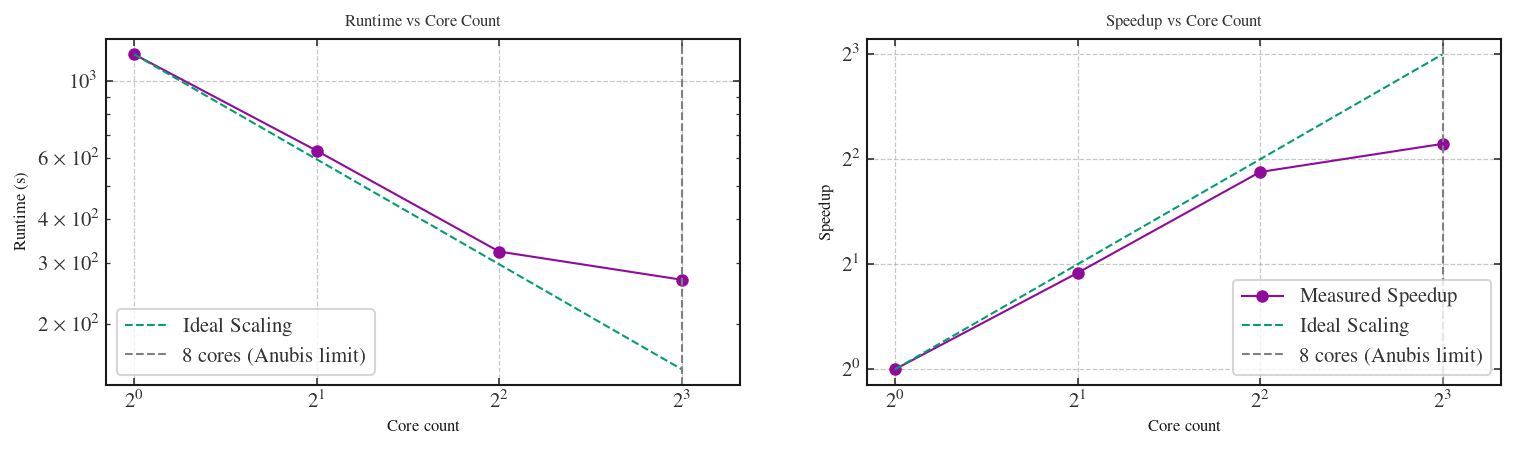

In [95]:
core_counts = np.array([1, 2, 4, 8])
runtimes = np.array([1190.32, 630.02, 323.64, 268.74])

fig, axes = plt.subplots(1, 2, figsize=(12, 3), dpi=150)

axes[0].plot(core_counts, runtimes, marker='o')
axes[0].plot(
    core_counts,
    runtimes[0] / core_counts,
    linestyle='--',
    label='Ideal Scaling'
)
axes[0].axvline(
    x=8,
    color='grey',
    linestyle='--',
    label='8 cores (Anubis limit)'
)
axes[0].set_xscale('log', base=2)
axes[0].set_yscale('log')
axes[0].set_xlabel('Core count')
axes[0].set_ylabel('Runtime (s)')
axes[0].set_title('Runtime vs Core Count')
axes[0].set_xlim(0.9, 10)
axes[0].grid(True)
axes[0].legend(loc='lower left')

speedup = runtimes[0] / runtimes
axes[1].plot(core_counts, speedup, marker='o', label='Measured Speedup')
axes[1].plot(core_counts, core_counts, linestyle='--', label='Ideal Scaling')

axes[1].axvline(
    x=8,
    color='grey',
    linestyle='--',
    label='8 cores (Anubis limit)'
)
axes[1].set_xscale('log', base=2)
axes[1].set_yscale('log', base=2)
axes[1].set_yticks([1, 2, 4, 8])
axes[1].set_xlabel('Core count')
axes[1].set_ylabel('Speedup')
axes[1].set_title('Speedup vs Core Count')
axes[1].set_xlim(0.9, 10)
axes[1].legend(loc='lower right')

plt.show()

On Serpens (10c/20T)

- 1T:  12.969u 0.012s 0:13.00 99.7%    0+0k 8+32io 0pf+0w
- 2T:  14.633u 0.007s 0:07.63 191.7%   0+0k 8+32io 0pf+0w
- 4T:  14.989u 0.008s 0:03.92 382.1%   0+0k 8+32io 0pf+0w
- 8T:  16.119u 0.019s 0:02.32 694.8%   0+0k 11576+32io 4pf+0w
- 16T: 18.026u 0.007s 0:01.31 1375.5%  0+0k 8+32io 0pf+0w
- 32T: 26.880u 0.031s 0:01.06 2538.6%  0+0k 8+32io 0pf+0w

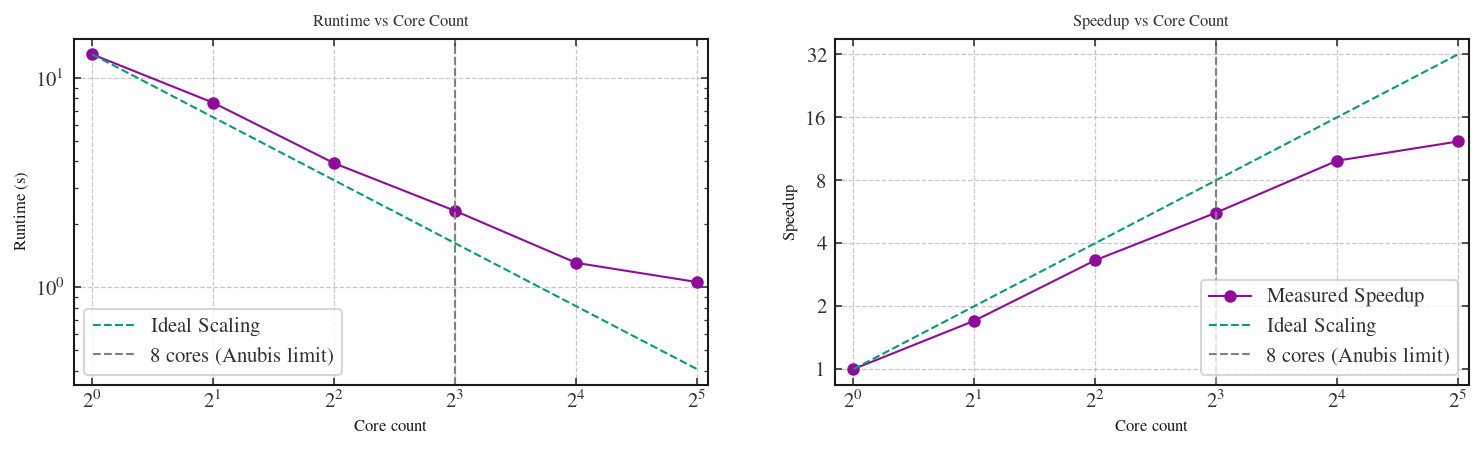

In [99]:
core_counts = np.array([1, 2, 4, 8, 16, 32])
runtimes = np.array([13.00, 7.63, 3.92, 2.32, 1.31, 1.06])

fig, axes = plt.subplots(1, 2, figsize=(12, 3), dpi=150)

axes[0].plot(core_counts, runtimes, marker='o')
axes[0].plot(
    core_counts,
    runtimes[0] / core_counts,
    linestyle='--',
    label='Ideal Scaling'
)
axes[0].axvline(
    x=8,
    color='grey',
    linestyle='--',
    label='8 cores (Anubis limit)'
)
axes[0].set_xscale('log', base=2)
axes[0].set_yscale('log')
axes[0].set_xlabel('Core count')
axes[0].set_ylabel('Runtime (s)')
axes[0].set_title('Runtime vs Core Count')
axes[0].set_xlim(0.9, 34)
axes[0].grid(True)
axes[0].legend(loc='lower left')

speedup = runtimes[0] / runtimes
axes[1].plot(core_counts, speedup, marker='o', label='Measured Speedup')
axes[1].plot(core_counts, core_counts, linestyle='--', label='Ideal Scaling')

axes[1].axvline(
    x=8,
    color='grey',
    linestyle='--',
    label='8 cores (Anubis limit)'
)
axes[1].set_xscale('log', base=2)
axes[1].set_yscale('log', base=2)
axes[1].set_yticks([2**0, 2**1, 2**2, 2**3, 2**4, 2**5])
axes[1].set_yticklabels(['1', '2', '4', '8', '16', '32'])
axes[1].set_xlabel('Core count')
axes[1].set_ylabel('Speedup')
axes[1].set_title('Speedup vs Core Count')
axes[1].set_xlim(0.9, 34)
axes[1].legend(loc='lower right')

plt.show()